# Cohort Analysis — Completed

This notebook implements cohort analysis for the curated project. Cohorts use each `customer_unique_id`'s **first observed eligible purchase month**. Eligible means delivered with at least one item, aligned with established sales metrics. Retention is the fraction of a cohort making at least one eligible purchase in a later calendar month. It is not continuous survival, subscription retention, or the percentage returning at any time.

Customers are deduplicated within month before counting. Month 0 is 100% by construction. A customer may skip a month and return later. Future, not-yet-observed ages are blank; an observable month with no repeat purchase is zero. The latest observed eligible month is marked as a potentially incomplete snapshot tail and excluded from pooled repeat-rate claims. Completeness of earlier months is not guaranteed by the source.


In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
while not (ROOT / 'src/analysis/eda.py').exists():
    if ROOT.parent == ROOT:
        raise RuntimeError('Run this notebook inside the project directory')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.analysis.customer_analytics import load_eligible, customer_analysis, cohort_analysis
OUT = ROOT / 'reports/completion_20261101/customer_analytics'
OUT.mkdir(parents=True, exist_ok=True)
eligible = load_eligible(ROOT)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.facecolor': 'white'})
print(f'Eligible delivered orders: {len(eligible):,}; customer IDs use customer_unique_id.')


Eligible delivered orders: 96,478; customer IDs use customer_unique_id.


In [2]:
cohort = cohort_analysis(eligible)
display(cohort['sizes'].rename('cohort_customers').to_frame())
display(cohort['rates'].round(3))
print('Latest observed eligible month:', cohort['last_observed_month'])


,cohort_customers
cohort_month,
2016-09,1
2016-10,262
2016-12,1
2017-01,717
2017-02,1628
2017-03,2503
2017-04,2256
2017-05,3451
2017-06,3037


age,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
cohort_month,,,,,,,,,,,,,,,,,,,,,
2016-09,100.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.0,0.000,0.000,0.0,0.0,0.0
2016-10,100.0,0.000,0.000,0.000,0.000,0.000,0.382,0.000,0.000,0.382,...,0.000,0.382,0.000,0.382,0.0,0.763,0.763,0.0,0.0,NaN
2016-12,100.0,100.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.0,0.000,0.000,NaN,NaN,NaN
2017-01,100.0,0.279,0.279,0.139,0.418,0.139,0.418,0.139,0.139,0.000,...,0.139,0.139,0.279,0.418,0.0,0.139,NaN,NaN,NaN,NaN
2017-02,100.0,0.184,0.307,0.123,0.430,0.123,0.246,0.184,0.123,0.184,...,0.123,0.061,0.061,0.184,0.0,NaN,NaN,NaN,NaN,NaN
2017-03,100.0,0.439,0.360,0.400,0.360,0.160,0.160,0.320,0.320,0.080,...,0.160,0.240,0.080,0.120,NaN,NaN,NaN,NaN,NaN,NaN
2017-04,100.0,0.621,0.222,0.177,0.266,0.266,0.355,0.310,0.310,0.177,...,0.089,0.089,0.133,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-05,100.0,0.464,0.464,0.290,0.290,0.319,0.406,0.145,0.261,0.261,...,0.174,0.203,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-06,100.0,0.494,0.395,0.428,0.296,0.395,0.362,0.230,0.132,0.198,...,0.230,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Latest observed eligible month: 2018-08


## Retention heatmap

Month 0 is omitted from the color scale to make small repeat rates visible. The plotted cells cover ages 1–12. Blank cells are not yet observable; the full matrix, including month 0 and later ages, is available above and in aggregate CSV outputs. The color scale is clipped at 1.5%; the numeric cell labels retain their actual percentages. Some cells in the final observed month may be incomplete.


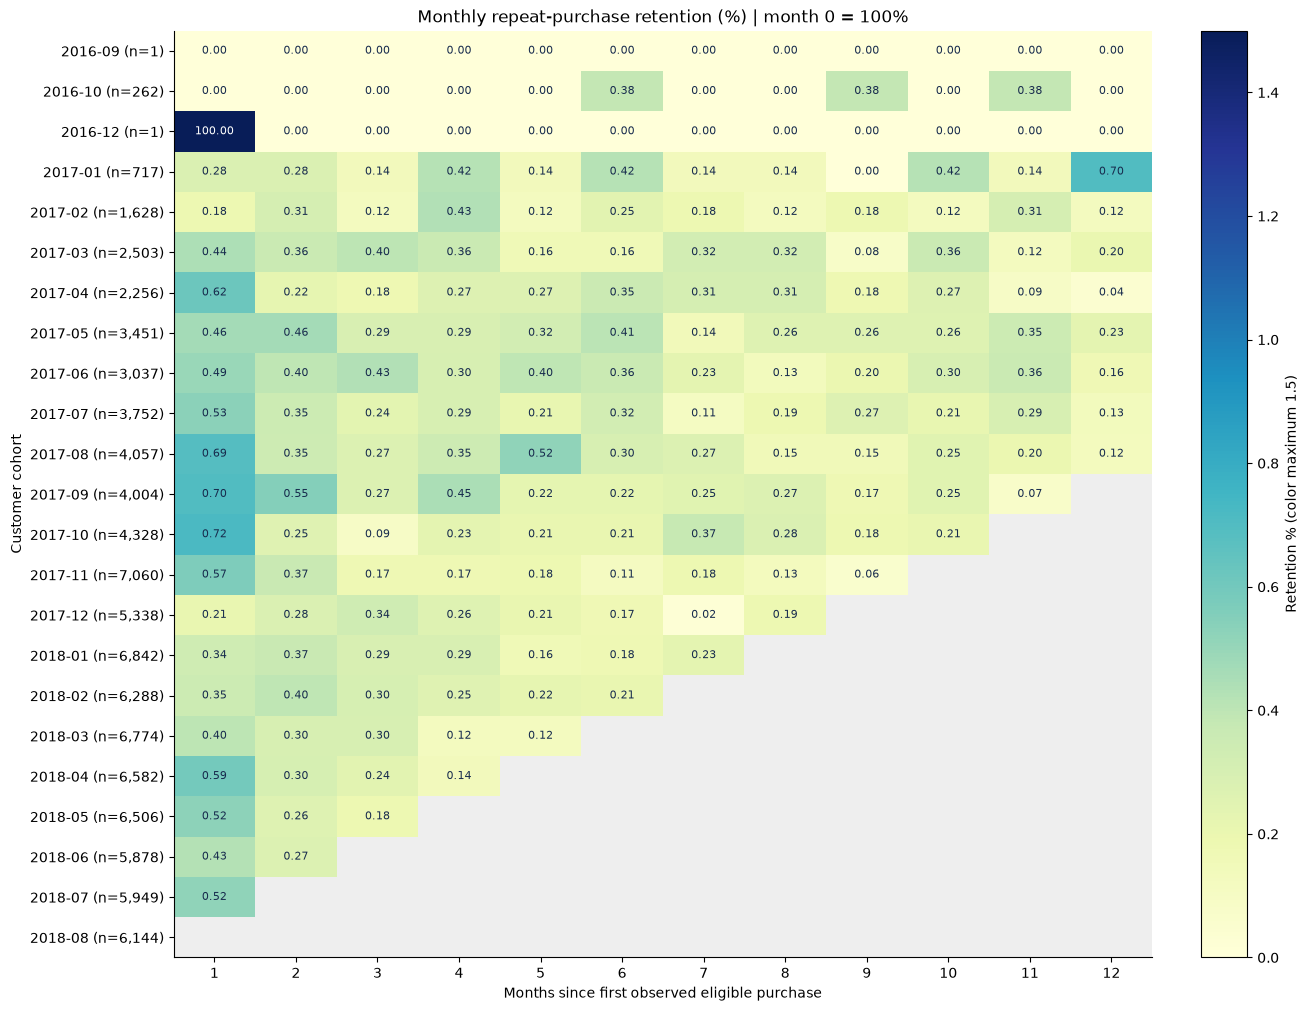

In [3]:
matrix = cohort['rates'].reindex(columns=range(1, 13))
fig, ax = plt.subplots(figsize=(13, 10), constrained_layout=True)
colors = plt.get_cmap('YlGnBu').copy()
colors.set_bad('#EEEEEE')
im = ax.imshow(matrix.to_numpy(dtype=float), cmap=colors, vmin=0, vmax=1.5, aspect='auto')
ax.set_xticks(range(12), labels=range(1,13))
ax.set_yticks(range(len(matrix)), labels=[f'{x} (n={cohort["sizes"].loc[x]:,})' for x in matrix.index])
ax.set(xlabel='Months since first observed eligible purchase', ylabel='Customer cohort', title='Monthly repeat-purchase retention (%) | month 0 = 100%')
for row in range(len(matrix)):
    for col in range(12):
        value = matrix.iloc[row, col]
        if pd.notna(value):
            ax.text(col, row, f'{value:.2f}', ha='center', va='center', fontsize=8, color='white' if value >= .85 else '#172B4D')
fig.colorbar(im, ax=ax, label='Retention % (color maximum 1.5)')
fig.savefig(OUT / 'cohort_retention_heatmap.png', dpi=160)
plt.show()


## Weighted retention and censoring

For each age, pooled retention divides total active customers by the sum of sizes of cohorts observable at that age, excluding activity in the last observed eligible month. Denominators change with age; this is not a single fixed-cohort survival curve. Small early cohorts are retained with explicit denominators so their volatile percentages are not mistaken for stable business patterns.


,active_customers,eligible_cohort_customers,eligible_cohorts,weighted_retention_pct
age,,,,
1,390.0,81265,21,0.4799
2,257.0,75387,20,0.3409
3,180.0,68881,19,0.2613
4,167.0,62299,18,0.2681
5,132.0,55525,17,0.2377
6,116.0,49237,16,0.2356
7,86.0,42395,15,0.2029
8,76.0,37057,14,0.2051
9,56.0,29997,13,0.1867


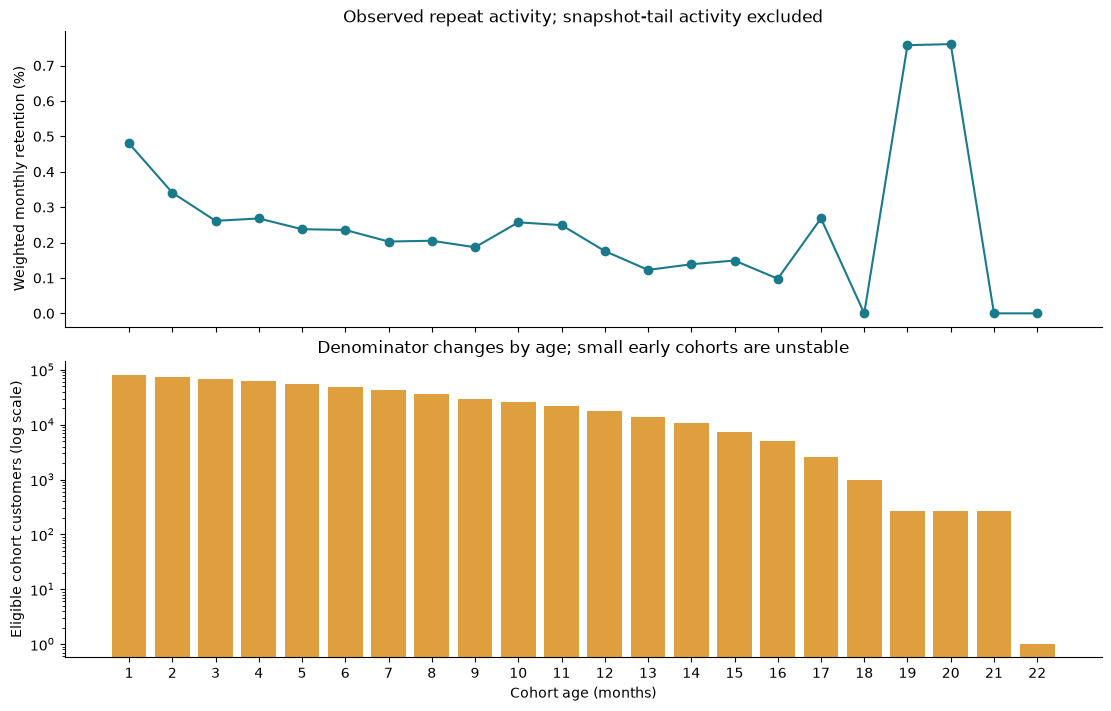

In [4]:
display(cohort['pooled'].round(4))
fig, axes = plt.subplots(2, 1, figsize=(11,7), sharex=True, constrained_layout=True)
p = cohort['pooled']
axes[0].plot(p.index, p.weighted_retention_pct, marker='o', color='#197A8C')
axes[0].set(ylabel='Weighted monthly retention (%)', title='Observed repeat activity; snapshot-tail activity excluded')
axes[1].bar(p.index, p.eligible_cohort_customers, color='#E09F3E')
axes[1].set_yscale('log')
axes[1].set(xlabel='Cohort age (months)', ylabel='Eligible cohort customers (log scale)', title='Denominator changes by age; small early cohorts are unstable')
axes[1].set_xticks(p.index)
fig.savefig(OUT / 'cohort_weighted_retention.png', dpi=160)
plt.show()


In [5]:
age1 = cohort['pooled'].loc[1]
display(Markdown(f"**Interpretation:** At age 1, {int(age1.active_customers):,} repeat-active customers / {int(age1.eligible_cohort_customers):,} eligible cohort customers gives {age1.weighted_retention_pct:.3f}% weighted monthly retention, excluding the snapshot tail. This differs from the all-window repeat customer rate because it measures purchases in one specific later month. Consider category-specific repeat-purchase experiments; do not label every inactive customer churned in this non-contractual marketplace."))
assert np.allclose(cohort['rates'][0], 100)
assert cohort['sizes'].sum() == eligible.customer_unique_id.nunique()
assert cohort['rates'].stack().dropna().between(0,100).all()
assert cohort['long'].loc[~cohort['long'].observed, 'retention_pct'].isna().all()
print('PASS: cohort size, month-0, bounded rate and future-censoring assertions.')


**Interpretation:** At age 1, 390 repeat-active customers / 81,265 eligible cohort customers gives 0.480% weighted monthly retention, excluding the snapshot tail. This differs from the all-window repeat customer rate because it measures purchases in one specific later month. Consider category-specific repeat-purchase experiments; do not label every inactive customer churned in this non-contractual marketplace.

PASS: cohort size, month-0, bounded rate and future-censoring assertions.
